# 07 · Procesos puntuales: localización de bancos y cajeros

| | |
|---|---|
| **Pregunta** | ¿Las sucursales y cajeros se localizan de forma completamente aleatoria (CSR), se agrupan, o su patrón se explica solo por dónde vive la población? |
| **Datos** | 395 bancos, ATM y casas de cambio georreferenciados en OpenStreetMap (16/10/2026); límites INEI 2026; centros poblados INEI con tipo urbano o rural. |
| **Escalas** | (A) Trujillo metropolitano, la zona mejor mapeada; (B) toda la región, con un modelo de intensidad no homogénea. |
| **Métodos** | Prueba de cuadrantes, índice de Clark-Evans, funciones G, F, K y L con envolventes de simulación bajo CSR; estimación kernel de la intensidad; proceso de Poisson no homogéneo log-lineal (aproximación de Berman-Turner por píxeles); simulación por adelgazamiento (Lewis-Shedler); función K no homogénea (Baddeley, Møller y Waagepetersen, 2000). |
| **Salidas** | `outputs/figuras/07_*.png` · `data/processed/intensidad_ipp_grilla.csv`. |

**Limitación declarada:** OSM registra una fracción de lo que reporta la SBS (≈ 395 puntos frente a ≈ 4 900 ATM),
por eso la inferencia de la escala A se restringe a una ciudad con buena cobertura y la escala B se interpreta
como el patrón de la oferta visible, no del total.

In [1]:
from pathlib import Path
import warnings

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from pointpats import QStatistic, f_test, g_test, l_test
from scipy.spatial import cKDTree
from scipy.stats import gaussian_kde
from shapely.geometry import box

warnings.filterwarnings("ignore")
rng = np.random.default_rng(2026)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed"
FIG = ROOT / "outputs" / "figuras"
CRS = "EPSG:32717"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Datos y depuración

In [2]:
gpkg = DATA / "geobanca_norte.gpkg"
distritos = gpd.read_file(gpkg, layer="distritos").to_crs(CRS)
puntos = gpd.read_file(gpkg, layer="osm_bancos_atm").to_crs(CRS)
ccpp = gpd.read_file(gpkg, layer="centros_poblados").to_crs(CRS)

# Un banco y su ATM suelen estar mapeados como dos objetos en el mismo local: se fusionan los puntos a menos de 15 m
xy = np.column_stack([puntos.geometry.x, puntos.geometry.y])
pares = cKDTree(xy).query_pairs(r=15)
descartar = {j for i, j in pares}
sitios = puntos.drop(index=puntos.index[list(descartar)]).reset_index(drop=True)
print(f"Objetos OSM: {len(puntos)} | sitios únicos tras fusionar duplicados a < 15 m: {len(sitios)}")

cobertura = (sitios.merge(distritos[["ubigeo", "provincia"]], on="ubigeo").groupby("provincia").size().rename("sitios_osm")
             .to_frame().join(distritos.groupby("provincia")[["n_atm", "n_oficinas"]].sum()))
cobertura["osm / (ATM + oficinas SBS)"] = cobertura["sitios_osm"] / (cobertura["n_atm"] + cobertura["n_oficinas"])
cobertura.sort_values("sitios_osm", ascending=False).head(8).round(3)

Objetos OSM: 395 | sitios únicos tras fusionar duplicados a < 15 m: 349


,sitios_osm,n_atm,n_oficinas,osm / (ATM + oficinas SBS)
provincia,,,,
TRUJILLO,99,1031.0,58.0,0.091
PIURA,56,1124.0,71.0,0.047
CHICLAYO,41,836.0,69.0,0.045
CAJAMARCA,26,331.0,30.0,0.072
MORROPON,17,54.0,24.0,0.218
AYABACA,12,26.0,13.0,0.308
TALARA,11,227.0,22.0,0.044
LAMBAYEQUE,9,118.0,34.0,0.059


## Escala A · Trujillo metropolitano

Ventana de estudio: los seis distritos de la conurbación (Trujillo, Víctor Larco Herrera, La Esperanza,
El Porvenir, Florencia de Mora y Alto Trujillo). La elección de la ventana condiciona todas las pruebas: una
ventana que incluya cerros o desierto vacío exageraría el agrupamiento.

In [3]:
URBANOS = ["TRUJILLO", "VICTOR LARCO HERRERA", "LA ESPERANZA", "EL PORVENIR", "FLORENCIA DE MORA", "ALTO TRUJILLO"]
vent_gdf = distritos[(distritos["provincia"] == "TRUJILLO") & (distritos["distrito"].isin(URBANOS))]
ventana = vent_gdf.union_all().simplify(25)   # simplificación de 25 m: acelera las simulaciones sin cambiar el área
pts_tru = sitios[sitios.within(ventana)]
coords = np.column_stack([pts_tru.geometry.x, pts_tru.geometry.y])
area_km2 = ventana.area / 1e6
lam = len(coords) / area_km2
print(f"n = {len(coords)} sitios | área = {area_km2:.1f} km² | intensidad media = {lam:.2f} sitios/km²")

n = 92 sitios | área = 112.3 km² | intensidad media = 0.82 sitios/km²


### A1. Prueba de cuadrantes y vecino más cercano

- **Cuadrantes:** bajo CSR, los conteos por celda siguen una Poisson y el estadístico χ² = Σ(O−E)²/E compara
  la dispersión observada con la esperada.
- **Clark-Evans:** R = d̄_obs / d̄_CSR, con d̄_CSR = 1 / (2√λ). R < 1 indica agrupamiento; R > 1, regularidad.

In [4]:
qs = QStatistic(coords, shape="rectangle", nx=6, ny=6)
print(f"Cuadrantes 6x6: chi2 = {qs.chi2:.1f}, gl = {qs.df}, p = {qs.chi2_pvalue:.2e}")

d_nn = cKDTree(coords).query(coords, k=2)[0][:, 1]
d_esp = 0.5 / np.sqrt(len(coords) / ventana.area)
R = d_nn.mean() / d_esp
se = 0.26136 / np.sqrt(len(coords) ** 2 / ventana.area)
z = (d_nn.mean() - d_esp) / se
print(f"Clark-Evans: distancia media al vecino más cercano = {d_nn.mean():.0f} m (CSR: {d_esp:.0f} m) | R = {R:.3f}, z = {z:.2f}")

Cuadrantes 6x6: chi2 = 326.7, gl = 35, p = 4.88e-49
Clark-Evans: distancia media al vecino más cercano = 224 m (CSR: 552 m) | R = 0.406, z = -10.89


### A2. Funciones de distancia con envolventes de simulación

Se comparan las funciones empíricas con 199 realizaciones de CSR dentro de la misma ventana:

- **G(r):** distribución de la distancia de cada sitio a su vecino más cercano. Por encima de la envolvente → agrupamiento.
- **F(r):** distancia de puntos arbitrarios del espacio al sitio más cercano (espacio vacío). Por debajo → agrupamiento.
- **K(r) y L(r) = √(K/π):** número esperado de sitios a distancia r de un sitio típico, dividido por λ. Bajo CSR,
  L(r) = r; se grafica L(r) − r para leer directamente el exceso de vecinos.

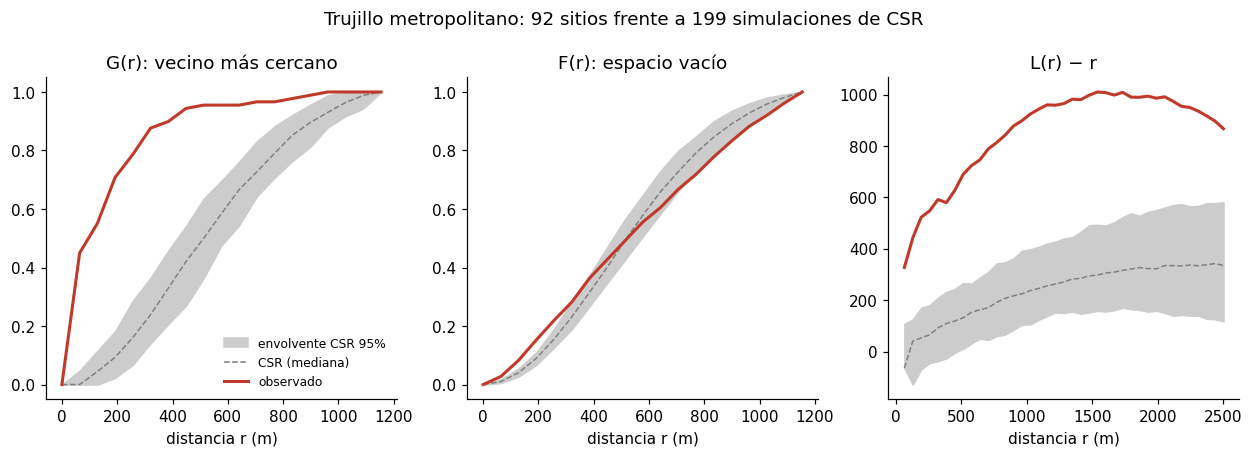

,p-valor mínimo en el rango
G,0.000
F,0.000
L,0.005


In [5]:
dist = np.linspace(0, 2500, 40)
NSIM = 199
res = {
    "G": g_test(coords, hull=ventana, support=dist[dist <= 1200], keep_simulations=True, n_simulations=NSIM),
    "F": f_test(coords, hull=ventana, support=dist[dist <= 1200], keep_simulations=True, n_simulations=NSIM),
    "L": l_test(coords, hull=ventana, support=dist[dist > 0], keep_simulations=True, n_simulations=NSIM),
}

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (nombre, r) in zip(axes, res.items()):
    sims = np.asarray(r.simulations)
    obs = np.asarray(r.statistic)
    x = np.asarray(r.support)
    if nombre == "L":
        sims, obs = sims - x, obs - x
    lo, hi = np.nanpercentile(sims, 2.5, axis=0), np.nanpercentile(sims, 97.5, axis=0)
    ax.fill_between(x, lo, hi, color="#cccccc", label="envolvente CSR 95%")
    ax.plot(x, np.nanmedian(sims, axis=0), color="grey", linestyle="--", linewidth=1, label="CSR (mediana)")
    ax.plot(x, obs, color="#c0392b", linewidth=2, label="observado")
    ax.set_xlabel("distancia r (m)")
    ax.set_title({"G": "G(r): vecino más cercano", "F": "F(r): espacio vacío", "L": "L(r) − r"}[nombre])
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle(f"Trujillo metropolitano: {len(coords)} sitios frente a {NSIM} simulaciones de CSR", y=1.04)
fig.savefig(FIG / "07_funciones_distancia_trujillo.png", bbox_inches="tight")
plt.show()

pd.DataFrame({k: {"p-valor mínimo en el rango": float(np.nanmin(np.asarray(v.pvalue)))} for k, v in res.items()}).T

### A3. Intensidad kernel

Estimador gaussiano de la intensidad λ(s) con ancho de banda de Scott. Muestra dónde se concentra la oferta
dentro de la ciudad: la superficie es el insumo descriptivo del que parte el modelo de la escala B.

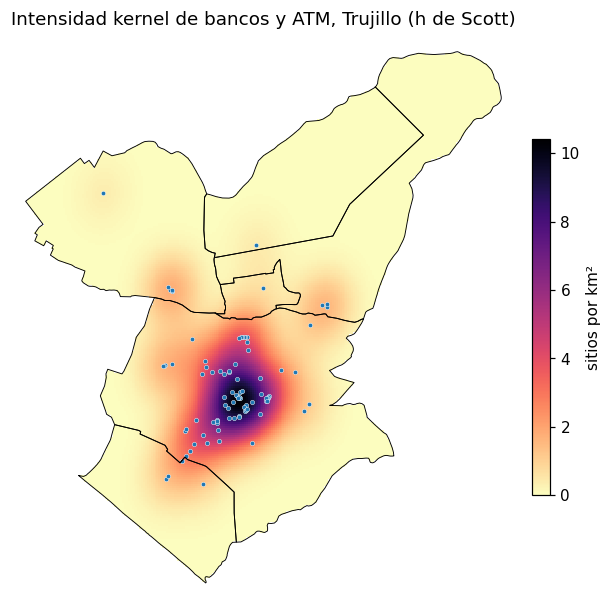

In [6]:
kde = gaussian_kde(coords.T, bw_method="scott")
xmin, ymin, xmax, ymax = ventana.bounds
gx, gy = np.meshgrid(np.linspace(xmin, xmax, 250), np.linspace(ymin, ymax, 250))
dens = kde(np.vstack([gx.ravel(), gy.ravel()])).reshape(gx.shape) * len(coords) * 1e6   # sitios por km²
fuera = ~gpd.GeoSeries(gpd.points_from_xy(gx.ravel(), gy.ravel()), crs=CRS).within(ventana).to_numpy().reshape(gx.shape)
dens = np.ma.array(dens, mask=fuera)

fig, ax = plt.subplots(figsize=(7, 7))
im = ax.pcolormesh(gx, gy, dens, cmap="magma_r", shading="auto")
vent_gdf.boundary.plot(ax=ax, color="black", linewidth=0.6)
ax.scatter(coords[:, 0], coords[:, 1], s=8, color="#1f77b4", edgecolor="white", linewidth=0.3)
fig.colorbar(im, ax=ax, shrink=0.6, label="sitios por km²")
ax.set_title(f"Intensidad kernel de bancos y ATM, Trujillo (h de Scott)")
ax.set_axis_off()
fig.savefig(FIG / "07_kernel_trujillo.png", bbox_inches="tight")
plt.show()

## Escala B · Región completa: proceso de Poisson no homogéneo

Que los sitios estén agrupados no significa que exista "contagio" entre ellos: pueden estar donde está la
demanda. Se modela la intensidad de primer orden como

$$\lambda(s) = \exp\{\beta_0 + \beta_1 \log \text{densidad}(s) + \beta_2\, \%\text{urbana}(s) + \beta_3\, d_{\text{urbano}}(s)\}$$

donde $d_{\text{urbano}}$ es la distancia (km) al centro poblado urbano más cercano. Se ajusta por la
aproximación de píxeles: con celdas de 3 km, los conteos $N_c \sim \text{Poisson}(\lambda_c |c|)$ y el
modelo es un GLM de Poisson con *offset* log(área).

In [7]:
region = distritos.union_all().simplify(200)
TAM = 3000  # m
xmin, ymin, xmax, ymax = region.bounds
xs, ys = np.meshgrid(np.arange(xmin, xmax, TAM), np.arange(ymin, ymax, TAM))
xs, ys = xs.ravel(), ys.ravel()
centros = gpd.GeoSeries(gpd.points_from_xy(xs + TAM / 2, ys + TAM / 2), crs=CRS)
dentro = centros.within(region).to_numpy()
celdas = gpd.GeoDataFrame(geometry=[box(x, y, x + TAM, y + TAM) for x, y in zip(xs[dentro], ys[dentro])], crs=CRS)
celdas["area_km2"] = TAM**2 / 1e6
cent = gpd.GeoDataFrame(geometry=centros[dentro].reset_index(drop=True), crs=CRS)

# Covariables por celda
cent = gpd.sjoin_nearest(cent, distritos[["ubigeo", "densidad_hab_km2", "pct_urbana", "geometry"]], how="left")
cent = cent[~cent.index.duplicated()]
urb = ccpp[ccpp["tipo"] == "Urban"]
d_urb, _ = cKDTree(np.column_stack([urb.geometry.x, urb.geometry.y])).query(np.column_stack([cent.geometry.x, cent.geometry.y]))
celdas["log_densidad"] = np.log(cent["densidad_hab_km2"].to_numpy())
celdas["pct_urbana"] = cent["pct_urbana"].to_numpy()
celdas["dist_urbano_km"] = d_urb / 1000

# Conteos
idx = gpd.sjoin(sitios[["geometry"]], celdas[["geometry"]], how="inner", predicate="within")["index_right"]
celdas["n"] = idx.value_counts().reindex(celdas.index, fill_value=0).to_numpy()
celdas = celdas.dropna(subset=["log_densidad", "pct_urbana"]).reset_index(drop=True)
print(f"Celdas: {len(celdas)} | sitios asignados: {celdas['n'].sum()} | celdas con al menos un sitio: {(celdas['n'] > 0).sum()}")

Celdas: 12532 | sitios asignados: 337 | celdas con al menos un sitio: 85


In [8]:
X = sm.add_constant(celdas[["log_densidad", "pct_urbana", "dist_urbano_km"]])
ipp = sm.GLM(celdas["n"], X, family=sm.families.Poisson(), offset=np.log(celdas["area_km2"])).fit()
csr = sm.GLM(celdas["n"], np.ones((len(celdas), 1)), family=sm.families.Poisson(), offset=np.log(celdas["area_km2"])).fit()
print(ipp.summary2().tables[1].round(4))
tabla = pd.DataFrame({"coef": ipp.params, "IRR = exp(coef)": np.exp(ipp.params),
                      "IC95% inf": np.exp(ipp.conf_int()[0]), "IC95% sup": np.exp(ipp.conf_int()[1])}).round(3)
lr = 2 * (ipp.llf - csr.llf)
print(f"Dispersión de Pearson (χ²/gl) = {ipp.pearson_chi2 / ipp.df_resid:.2f}  (< 1: no hay sobredispersión que obligue a un modelo binomial negativo)")
print(f"\nRazón de verosimilitudes Poisson no homogéneo vs homogéneo: {lr:.1f} (gl = 3) | AIC {csr.aic:.0f} -> {ipp.aic:.0f}")
tabla

                 Coef.  Std.Err.         z  P>|z|  [0.025  0.975]
const          -7.2407    0.2178  -33.2466  0.000 -7.6676 -6.8139
log_densidad    0.8871    0.0348   25.4954  0.000  0.8189  0.9553
pct_urbana      0.0071    0.0027    2.6527  0.008  0.0019  0.0123
dist_urbano_km -1.0255    0.0047 -219.1169  0.000 -1.0347 -1.0163
Dispersión de Pearson (χ²/gl) = 0.49  (< 1: no hay sobredispersión que obligue a un modelo binomial negativo)

Razón de verosimilitudes Poisson no homogéneo vs homogéneo: 2437.3 (gl = 3) | AIC 4121 -> 1690


,coef,IRR = exp(coef),IC95% inf,IC95% sup
const,-7.241,0.001,0.000,0.001
log_densidad,0.887,2.428,2.268,2.599
pct_urbana,0.007,1.007,1.002,1.012
dist_urbano_km,-1.025,0.359,0.355,0.362


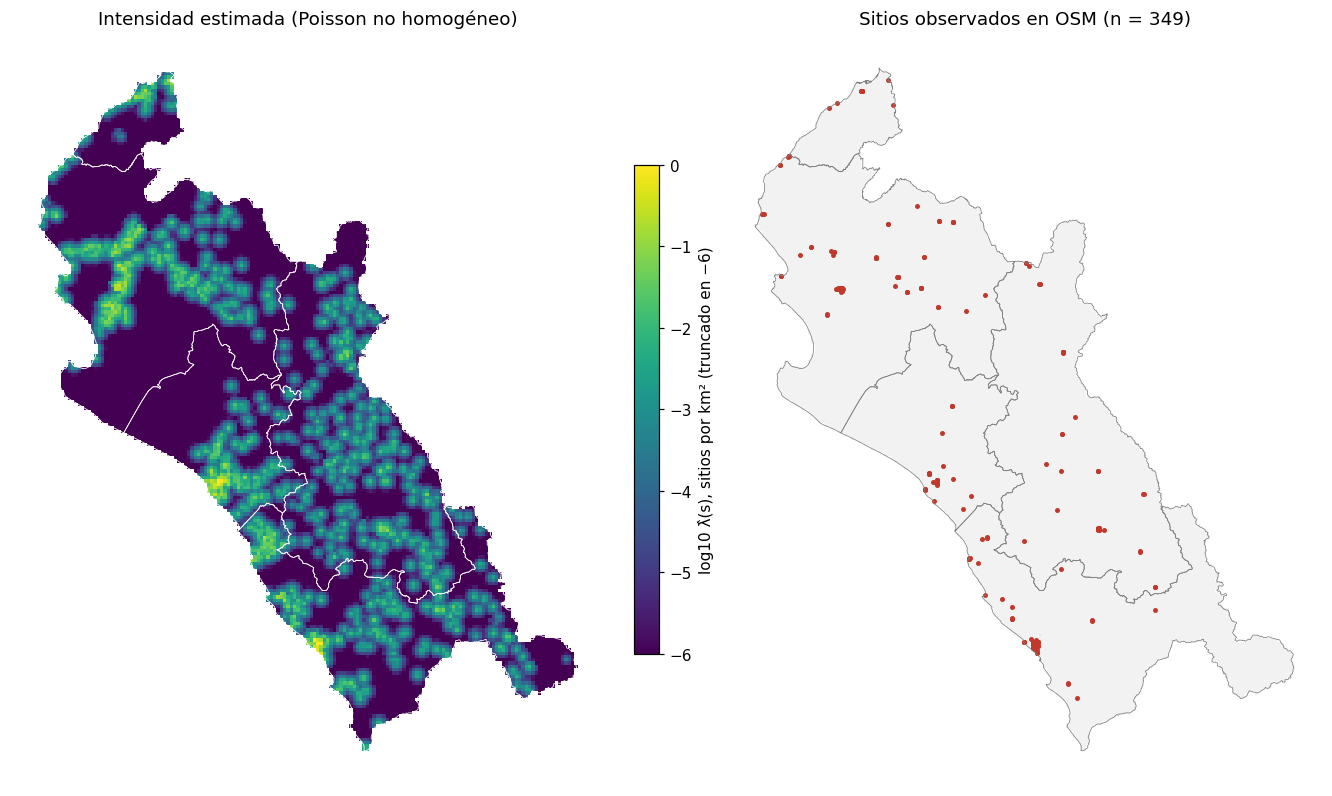

In [9]:
celdas["lambda_hat"] = ipp.predict(X, offset=np.zeros(len(celdas)))   # intensidad por km²
celdas[["log_densidad", "pct_urbana", "dist_urbano_km", "n", "lambda_hat", "area_km2"]].to_csv(DATA / "intensidad_ipp_grilla.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 7.5), constrained_layout=True)
celdas.plot(column=np.log10(celdas["lambda_hat"]).clip(lower=-6), cmap="viridis", ax=axes[0], linewidth=0, vmin=-6, vmax=0,
            legend=True, legend_kwds={"label": "log10 λ̂(s), sitios por km² (truncado en −6)", "shrink": 0.6})
distritos.dissolve("departamento").boundary.plot(ax=axes[0], color="white", linewidth=0.5)
axes[0].set_title("Intensidad estimada (Poisson no homogéneo)")
celdas.plot(ax=axes[1], color="#f2f2f2", linewidth=0)
distritos.dissolve("departamento").boundary.plot(ax=axes[1], color="grey", linewidth=0.5)
sitios.plot(ax=axes[1], markersize=5, color="#c0392b")
axes[1].set_title(f"Sitios observados en OSM (n = {len(sitios)})")
for ax in axes: ax.set_axis_off()
fig.savefig(FIG / "07_intensidad_ipp.png", bbox_inches="tight")
plt.show()

### B1. Simulación del proceso ajustado (adelgazamiento de Lewis-Shedler)

1. Se simula un Poisson homogéneo con intensidad λ_max sobre cada celda.
2. Cada punto se conserva con probabilidad λ(s)/λ_max.

El resultado es una realización del proceso no homogéneo ajustado. Se compara con una realización de CSR con
el mismo número esperado de puntos.

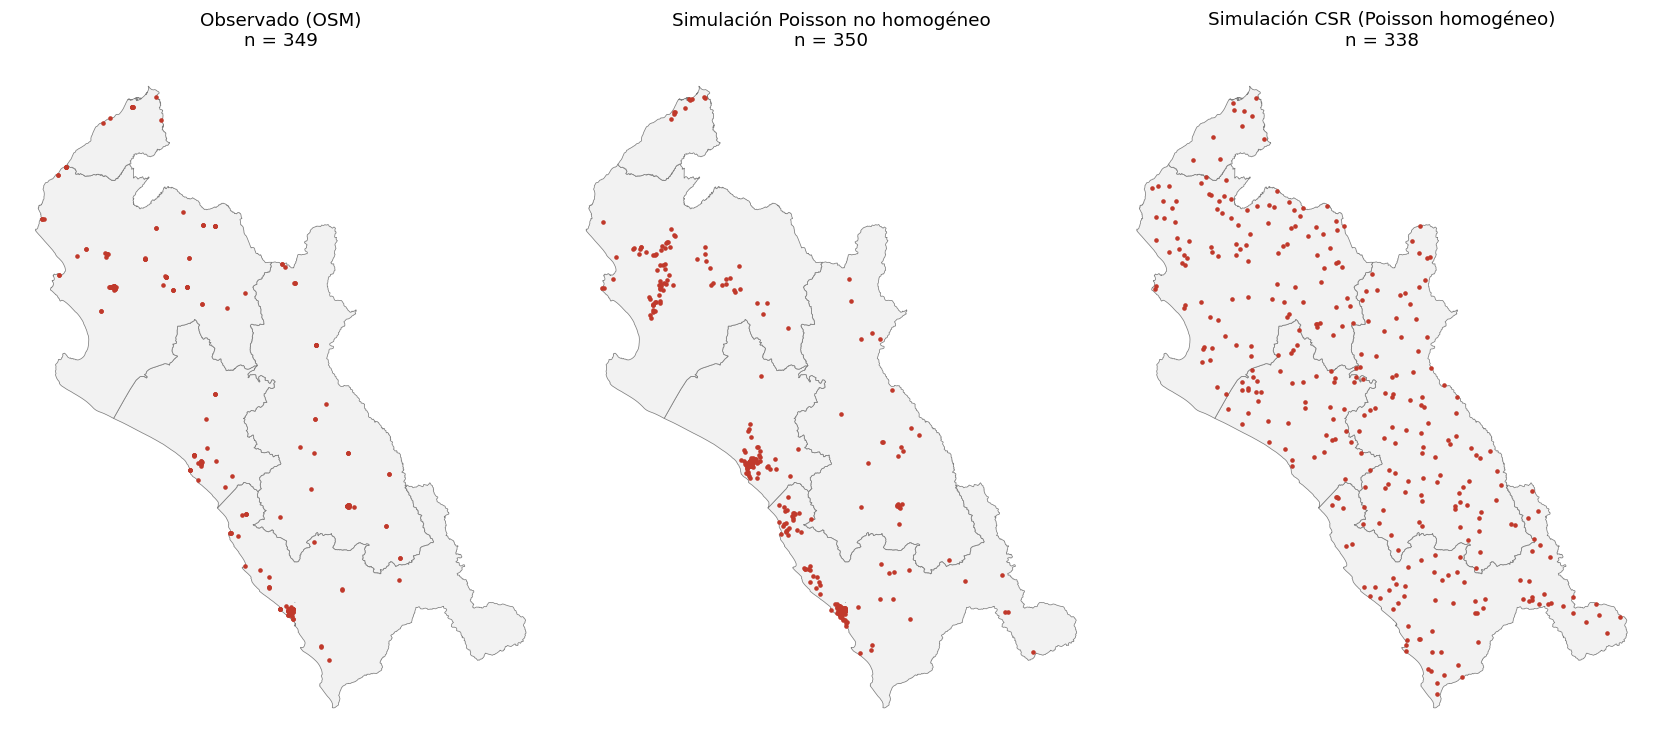

In [10]:
# Simulación por celdas: λ es constante dentro de cada celda de 3 km (aproximación de píxeles). Generar
# N_c ~ Poisson(λ_c |c|) puntos uniformes en cada celda equivale a adelgazar un Poisson homogéneo de
# intensidad λ_max con probabilidad de retención λ_c / λ_max (Lewis y Shedler, 1979).
def simular_ipp_rapido(celdas, rng, lam_col="lambda_hat", devolver_celda=False):
    n = rng.poisson(celdas[lam_col].to_numpy() * celdas["area_km2"].to_numpy())
    b = celdas.geometry.bounds.to_numpy()
    rep = np.repeat(np.arange(len(celdas)), n)
    xy_ = np.column_stack([rng.uniform(b[rep, 0], b[rep, 2]), rng.uniform(b[rep, 1], b[rep, 3])])
    return (xy_, rep) if devolver_celda else xy_

sim_ipp = simular_ipp_rapido(celdas, rng)
celdas["lambda_csr"] = len(sitios) / celdas["area_km2"].sum()
sim_csr = simular_ipp_rapido(celdas, rng, "lambda_csr")

fig, axes = plt.subplots(1, 3, figsize=(15, 7), constrained_layout=True)
for ax, (titulo, xy_) in zip(axes, [("Observado (OSM)", np.column_stack([sitios.geometry.x, sitios.geometry.y])),
                                    ("Simulación Poisson no homogéneo", sim_ipp),
                                    ("Simulación CSR (Poisson homogéneo)", sim_csr)]):
    distritos.dissolve("departamento").plot(ax=ax, color="#f2f2f2", edgecolor="grey", linewidth=0.5)
    ax.scatter(xy_[:, 0], xy_[:, 1], s=4, color="#c0392b")
    ax.set_title(f"{titulo}\nn = {len(xy_)}")
    ax.set_axis_off()
fig.savefig(FIG / "07_simulaciones_ipp_csr.png", bbox_inches="tight")
plt.show()

### B2. ¿Queda agrupamiento después de controlar la intensidad? Función K no homogénea

$$\hat K_{\text{inhom}}(r) = \frac{1}{|A|} \sum_{i}\sum_{j \ne i} \frac{\mathbf 1(d_{ij} \le r)}{\hat\lambda(s_i)\,\hat\lambda(s_j)}$$

Si el patrón observado queda dentro de la envolvente de 199 simulaciones del proceso ajustado, la intensidad de
primer orden (densidad, urbanización y distancia a centros urbanos) basta para explicar la localización. Si la
supera, hay agrupamiento adicional de segundo orden (competencia o arrastre entre entidades).

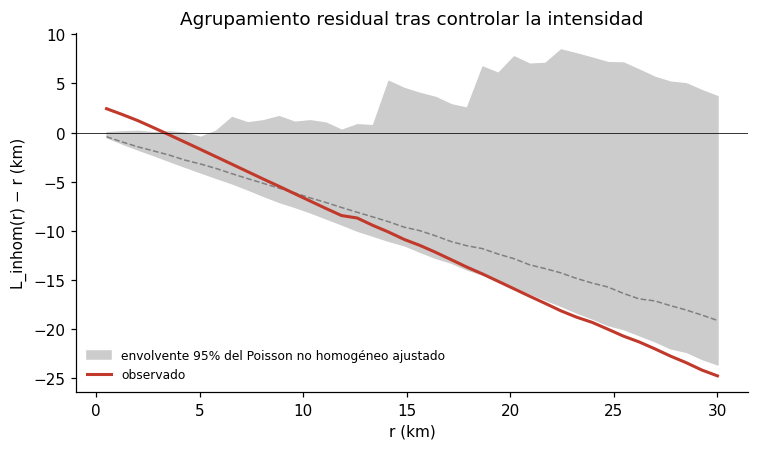

Radios con L observado por debajo de la envolvente: 15 de 40 (desde 19.4 km)
Radios con L observado por encima de la envolvente: 0.5 a 2.7692307692307696 km (4 de 40)


In [11]:
def lambda_en(xy_, celdas):
    g_ = gpd.GeoDataFrame(geometry=gpd.points_from_xy(*xy_.T), crs=CRS)
    j = gpd.sjoin(g_, celdas[["geometry", "lambda_hat"]], how="left", predicate="within")
    j = j[~j.index.duplicated()]
    return j["lambda_hat"].to_numpy() / 1e6   # por m²

def k_inhom(xy_, lam_, area, r):
    ok = ~np.isnan(lam_)
    xy_, lam_ = xy_[ok], lam_[ok]
    tree = cKDTree(xy_)
    pares = tree.query_pairs(r.max(), output_type="ndarray")
    d = np.linalg.norm(xy_[pares[:, 0]] - xy_[pares[:, 1]], axis=1)
    peso = 2.0 / (lam_[pares[:, 0]] * lam_[pares[:, 1]])
    return np.array([peso[d <= ri].sum() for ri in r]) / area

r = np.linspace(500, 30000, 40)
area_reg = celdas["area_km2"].sum() * 1e6
xy_obs = np.column_stack([sitios.geometry.x, sitios.geometry.y])
L_obs = np.sqrt(k_inhom(xy_obs, lambda_en(xy_obs, celdas), area_reg, r) / np.pi) - r

L_sim = []
for _ in range(199):
    s_xy, s_celda = simular_ipp_rapido(celdas, rng, devolver_celda=True)
    lam_s = celdas["lambda_hat"].to_numpy()[s_celda] / 1e6
    L_sim.append(np.sqrt(k_inhom(s_xy, lam_s, area_reg, r) / np.pi) - r)
L_sim = np.array(L_sim)

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.fill_between(r / 1000, np.percentile(L_sim, 2.5, 0) / 1000, np.percentile(L_sim, 97.5, 0) / 1000,
                color="#cccccc", label="envolvente 95% del Poisson no homogéneo ajustado")
ax.plot(r / 1000, np.median(L_sim, 0) / 1000, "--", color="grey", linewidth=1)
ax.plot(r / 1000, L_obs / 1000, color="#c0392b", linewidth=2, label="observado")
ax.axhline(0, color="black", linewidth=0.5)
ax.set_xlabel("r (km)"); ax.set_ylabel("L_inhom(r) − r (km)")
ax.set_title("Agrupamiento residual tras controlar la intensidad")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "07_k_inhomogenea.png", bbox_inches="tight")
plt.show()

fuera_inf = (L_obs < np.percentile(L_sim, 2.5, 0))
print(f"Radios con L observado por debajo de la envolvente: {fuera_inf.sum()} de {len(r)}"
      + (f" (desde {r[fuera_inf].min()/1000:.1f} km)" if fuera_inf.any() else ""))
fuera_sup = (L_obs > np.percentile(L_sim, 97.5, 0))
print(f"Radios con L observado por encima de la envolvente: {r[fuera_sup].min()/1000 if fuera_sup.any() else '-'}"
      f" a {r[fuera_sup].max()/1000 if fuera_sup.any() else '-'} km ({fuera_sup.sum()} de {len(r)})")

## Hallazgos

**Escala A · Trujillo metropolitano (92 sitios en 112 km²)**

1. **El patrón está fuertemente agrupado.** La prueba de cuadrantes rechaza CSR (χ² = 327 con 35 gl,
   p < 10⁻⁴⁸). El índice de Clark-Evans es R = 0,41 (z = −10,9): la distancia media al vecino más cercano es
   224 m, frente a 552 m esperados bajo CSR.
2. **El agrupamiento ocurre a todas las escalas analizadas.** G(r) queda por encima de la envolvente desde los
   primeros metros (45% de los sitios tiene otro a menos de 70 m) y L(r) − r supera la envolvente en todo el
   rango hasta 2,5 km, con un exceso máximo de ≈ 1 km cerca de 1,5 km. F(r) sigue cerca de CSR: la ciudad
   tiene grandes zonas sin oferta, pero el núcleo concentra casi todo.
3. **La intensidad kernel identifica un núcleo único**, el centro histórico de Trujillo (> 10 sitios por km²), y
   focos secundarios en La Esperanza, El Porvenir y Víctor Larco. Alto Trujillo y Florencia de Mora casi no tienen
   oferta visible.

**Escala B · Región completa (349 sitios, 12 532 celdas de 3 km)**

4. **La intensidad depende de la demanda.** En el Poisson no homogéneo, duplicar la densidad poblacional
   multiplica la intensidad por 2^0,887 ≈ 1,85; cada punto porcentual de población urbana la aumenta en 0,7%; y
   cada kilómetro de distancia al centro poblado urbano más cercano la reduce en 64% (IRR = 0,36). El modelo
   mejora de forma contundente al homogéneo (razón de verosimilitudes = 2 437 con 3 gl; AIC de 4 121 a 1 690).
5. **Queda agrupamiento de corto alcance que la demanda no explica.** La K no homogénea supera la envolvente
   entre 0,5 y 2,8 km: las entidades se instalan unas junto a otras más de lo que justifica la población
   (economías de aglomeración y competencia por el mismo mercado). A distancias largas el patrón observado queda
   por debajo de la envolvente: el término de distancia lineal concentra la intensidad más de lo observado.
6. **Implicancia de negocio:** la oferta se apila en los mismos centros urbanos. Un nuevo agente o EOB aporta más
   cobertura en los centros poblados alejados de la red actual, que es lo que optimiza el notebook 09.